**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Prepare

**Set global variable**

In [2]:
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

VEC_TXT_FOLDER = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
TXT_FNAME_ANNOT = "region.annotation.hic_intact_deep.loop.score.node.tsv"

**View files**

In [4]:
txt_fdiry = file.path(FD_RES, "region_annotation", "*", "summary")
txt_fname = TXT_FNAME_ANNOT
txt_fglob = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for(txt in vec){cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/region_annotation/fcc_astarr_macs_input_overlap/summary/region.annotation.hic_intact_deep.loop.score.node.tsv 
/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/region_annotation/fcc_astarr_macs_input_union/summary/region.annotation.hic_intact_deep.loop.score.node.tsv 


## Import data

### Import region annotation

In [5]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = TXT_FNAME_ANNOT
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})
names(lst) = VEC_TXT_FOLDER

### assign and show
lst_dat_region_annot_hic_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 53760    11

$fcc_astarr_macs_input_union
[1] 65084    11



Chrom,ChromStart,ChromEnd,Region,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,826796,828040,chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,4,1.938149,7.752596,0.3837763,1.5351050,-0.1816422,-0.7265690


In [6]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = "region.annotation.fcc_starrmpra_junke.group.label.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})

### assign and show
lst_dat_region_annot_fcc_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 150047      9

$fcc_astarr_macs_input_union
[1] 246862      9



Chrom,ChromStart,ChromEnd,Region,Distance2TSS,TSS_Proximity,TSS,Direction_Assay,Group
chr1,10038,10405,chr1:10038-10405,1469,Proximal,0,Inactive,Proximal:Inactive
chr1,14282,14614,chr1:14282-14614,2409,Distal,0,Inactive,Distal:Inactive
chr1,16025,16338,chr1:16025-16338,1099,Proximal,0,Inactive,Proximal:Inactive


In [7]:
53760
150047

[1] 53760

[1] 150047

In [8]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    dat_region_annot_fcc = lst_dat_region_annot_fcc_import[[txt_folder]]
    dat_region_annot_hic = lst_dat_region_annot_hic_import[[txt_folder]]

    ### read table
    vec = c("Chrom", "ChromStart", "ChromEnd", "Region")
    dat = dplyr::inner_join(
        dat_region_annot_fcc,
        dat_region_annot_hic,
        by = vec
    )
    return(dat)
})

### assign and show
lst_dat_region_annot_merge = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 53762    16

$fcc_astarr_macs_input_union
[1] 65086    16



Chrom,ChromStart,ChromEnd,Region,Distance2TSS,TSS_Proximity,TSS,Direction_Assay,Group,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,0,Proximal,1,Active,Proximal:Active,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,826796,828040,chr1:826796-828040,0,Proximal,1,Inactive,Proximal:Inactive,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,6570,Distal,0,Inactive,Distal:Inactive,4,1.938149,7.752596,0.3837763,1.5351050,-0.1816422,-0.7265690


In [9]:
idx_region = "fcc_astarr_macs_input_overlap"

In [10]:
### set text size
theme_text = theme(
    title      = element_text(size = 16),
    axis.title = element_text(size = 16),
    axis.text  = element_text(size = 16),
    #legend.title = element_text(size = 16),
    legend.title = element_blank(),
    legend.text  = element_text(size = 16)
)

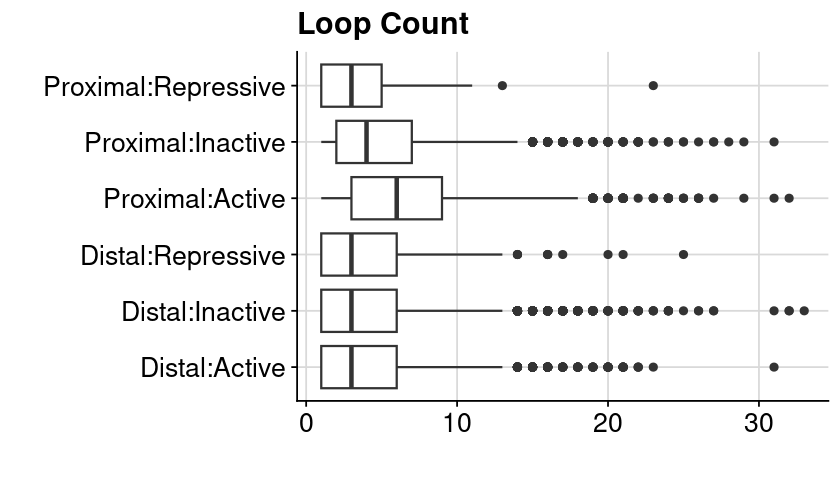

In [11]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Count, y=Group)) +
        geom_boxplot() +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Count", x = "", y = "") +
        theme_text
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_count = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

In [12]:
library(gghalves)

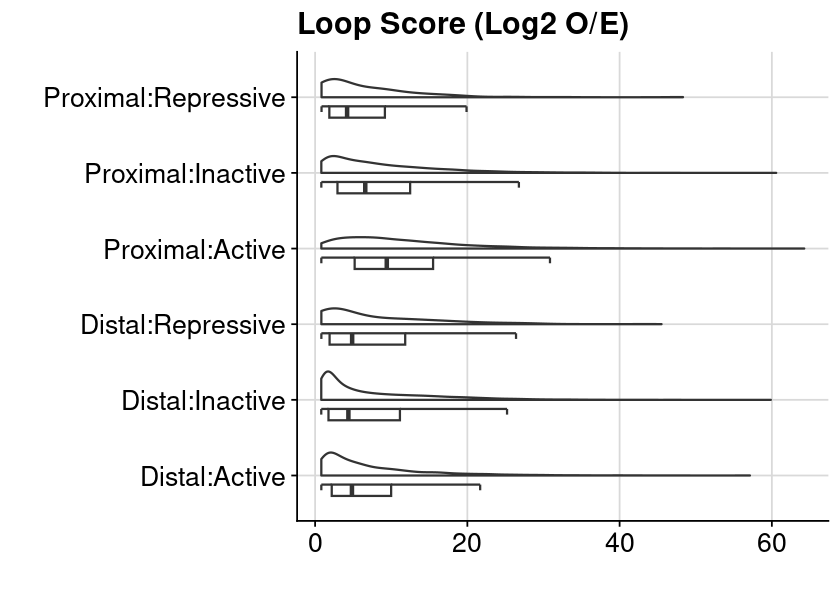

In [16]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Group, y=Loop_Score_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Log2 O/E)", x = "", y = "") +
        coord_flip() +
        theme_text
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=5, repr.plot.width=7)
print(gpt)

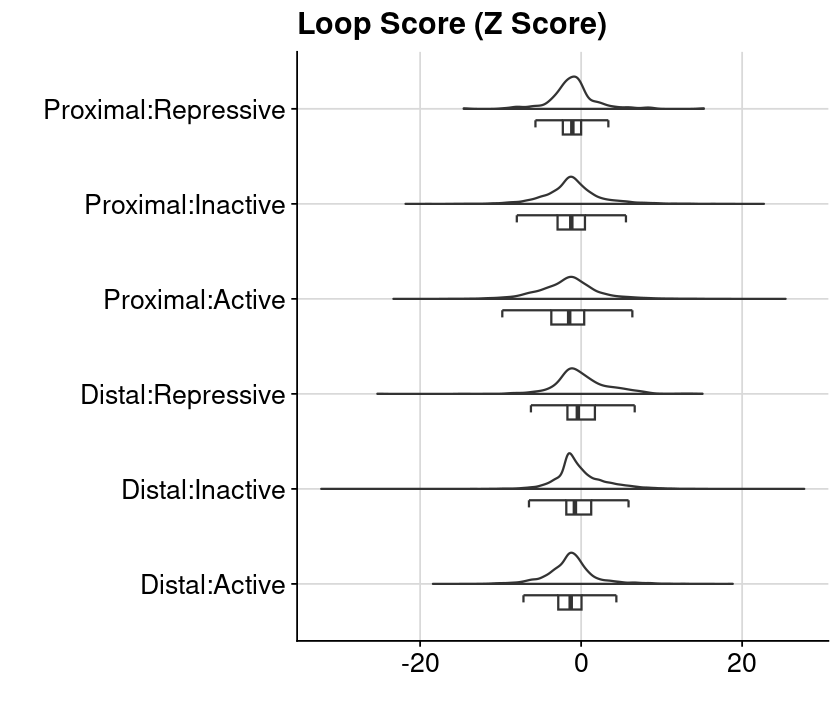

In [40]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Group, y=Loop_Zcore_DistSm_Sum)) +
        geom_half_violin(side = "r", trim = TRUE, alpha = 0.4, adjust = 1.2) +
        geom_half_boxplot(side = "l", width = 0.3, position = position_nudge(x = -0.12), outlier.shape = NA) +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Z Score)", x = "", y = "") +
        coord_flip() +
        theme_text
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_zcore = gpt
options(repr.plot.height=6, repr.plot.width=7)
print(gpt)

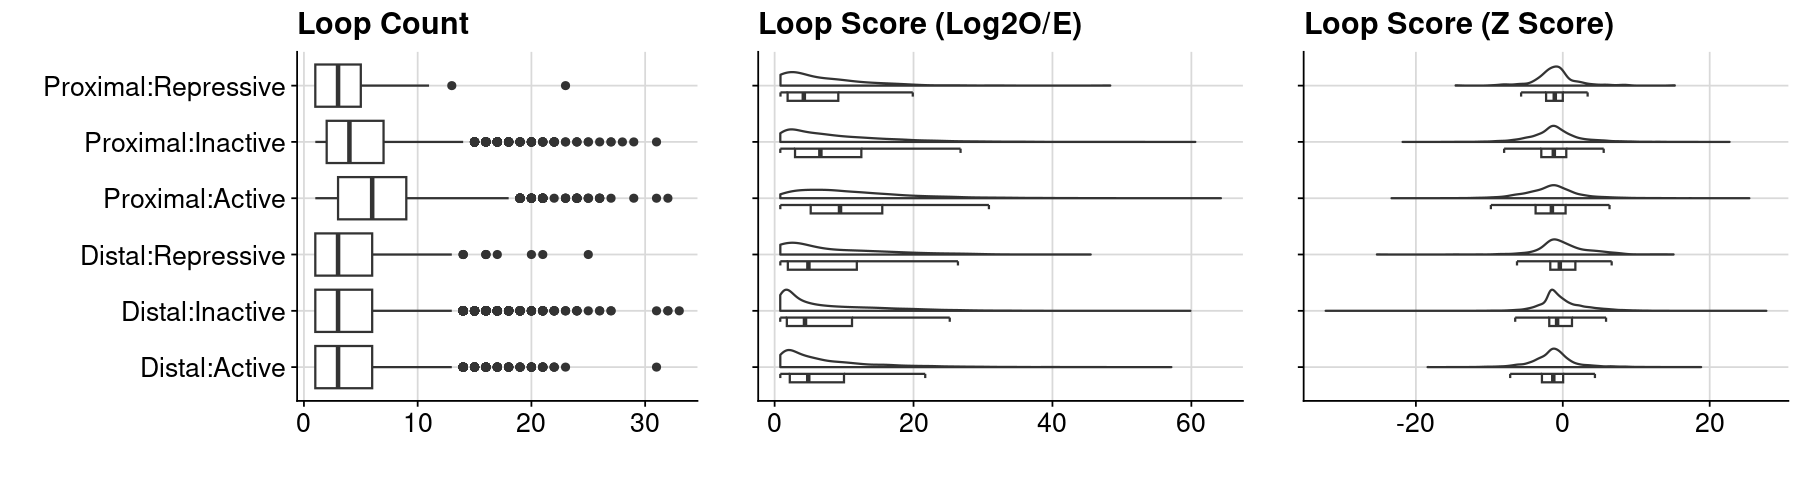

In [43]:
lst = list(
    gpt_export_loop_count,
    gpt_export_loop_score + theme(axis.text.y = element_blank()),
    gpt_export_loop_zcore + theme(axis.text.y = element_blank())
)
lst = lapply(lst, function(gpt){gpt + theme_text})

plt = plot_grid(plotlist = lst, nrow = 1, rel_widths = c(1.3,1,1))
options(repr.plot.height=4, repr.plot.width=15)
print(plt)

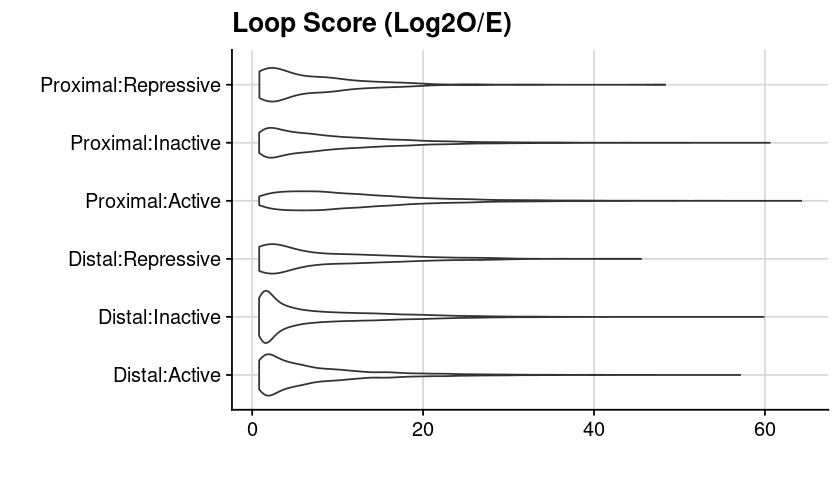

In [41]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Log2O/E)", x = "", y = "")
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_score = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

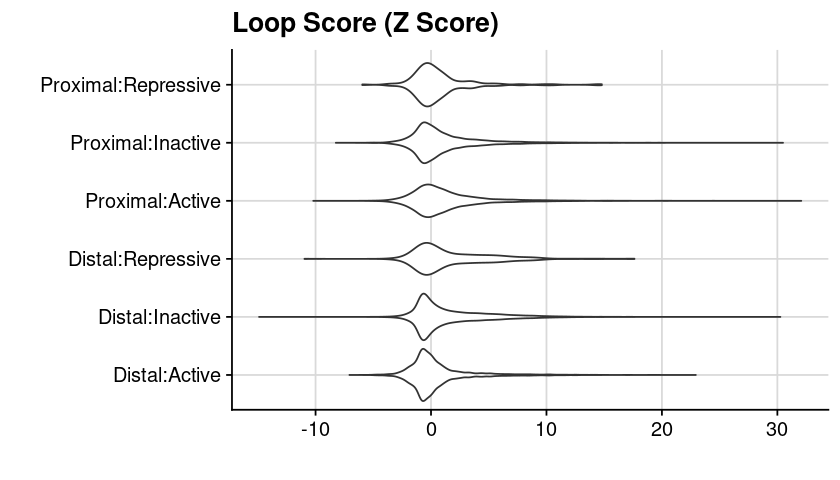

In [44]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_Global_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid() +
        labs(title = "Loop Score (Z Score)", x = "", y = "")
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_zcore = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

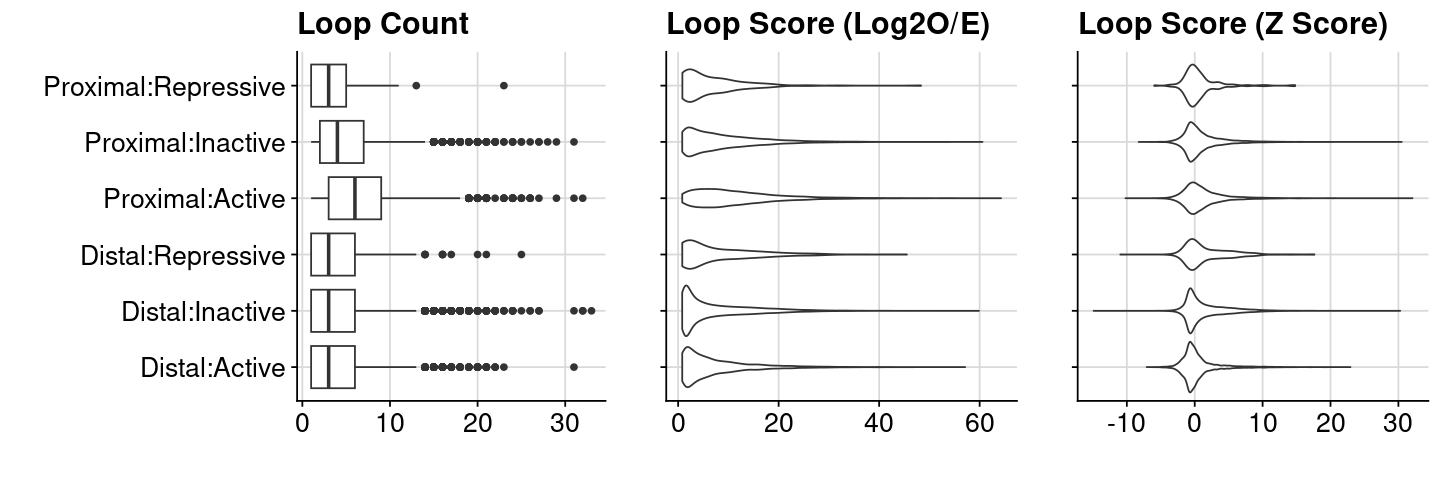

In [45]:
lst = list(
    gpt_export_loop_count,
    gpt_export_loop_score + theme(axis.text.y = element_blank()),
    gpt_export_loop_zcore + theme(axis.text.y = element_blank())
)
lst = lapply(lst, function(gpt){gpt + theme_text})

plt = plot_grid(plotlist = lst, nrow = 1, rel_widths = c(1.5,1,1))
options(repr.plot.height=4, repr.plot.width=12)
print(plt)

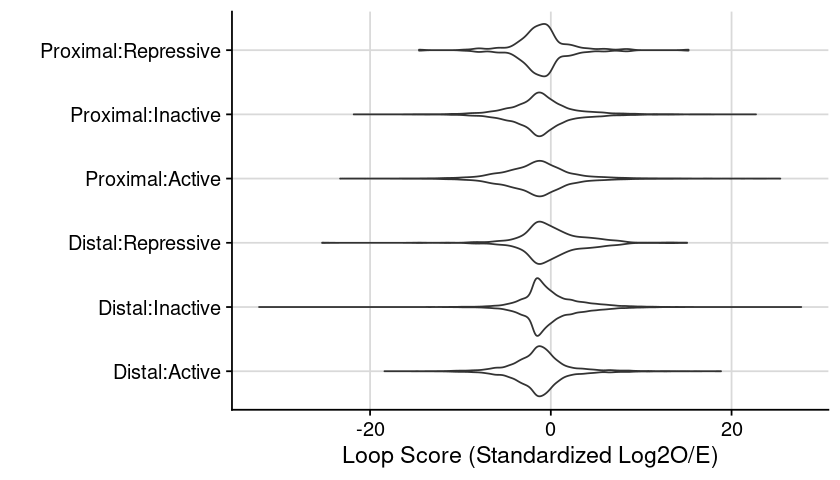

In [26]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Score (Standardized Log2O/E)", y = "")
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_zcore = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

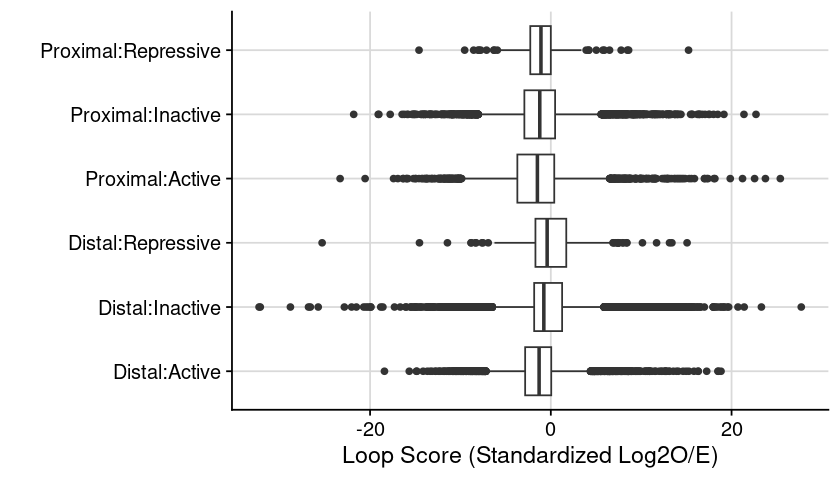

In [24]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum, y=Group)) +
        geom_boxplot() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Score (Standardized Log2O/E)", y = "")
    return(gpt)
})

gpt = lst[[idx_region]]
gpt_export_loop_zcore = gpt
options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

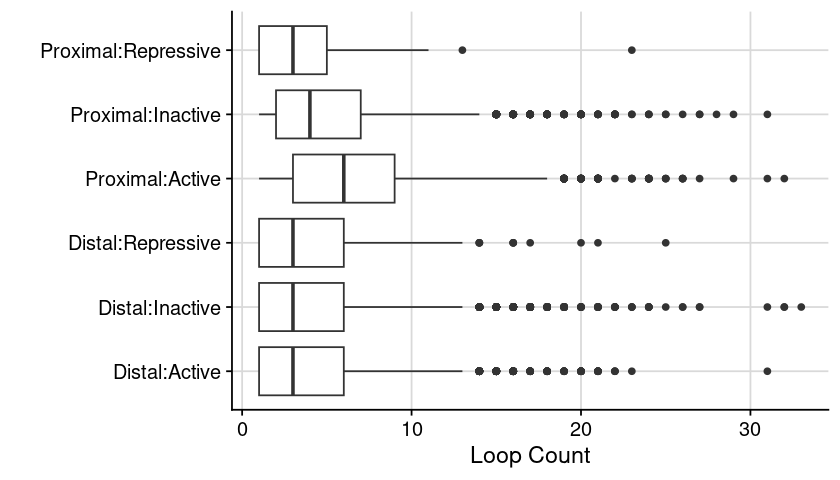

In [23]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Count, y=Group)) +
        geom_boxplot() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Count", y = "")
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

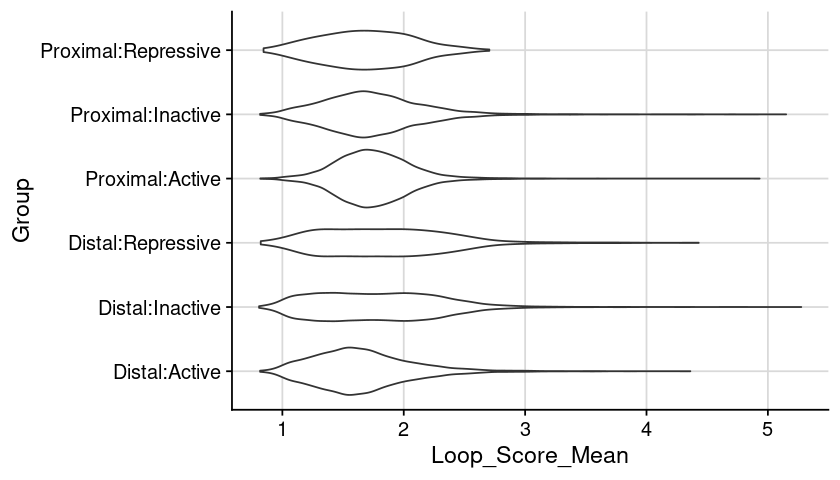

In [24]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score_Mean, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

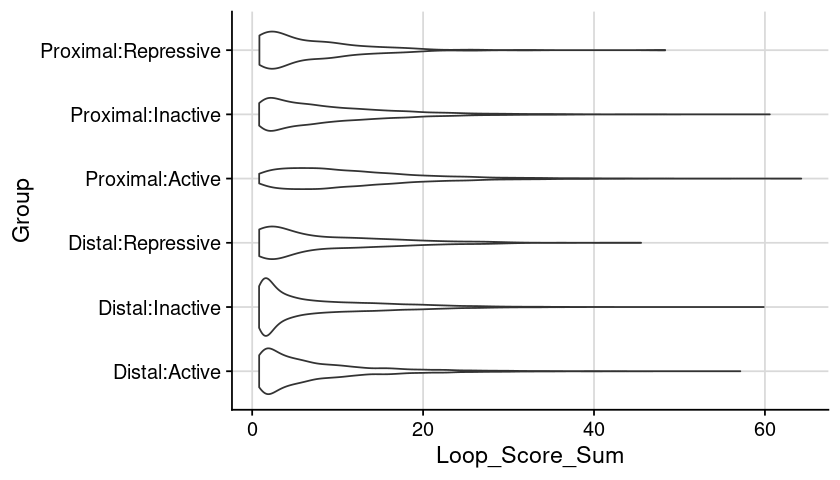

In [26]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

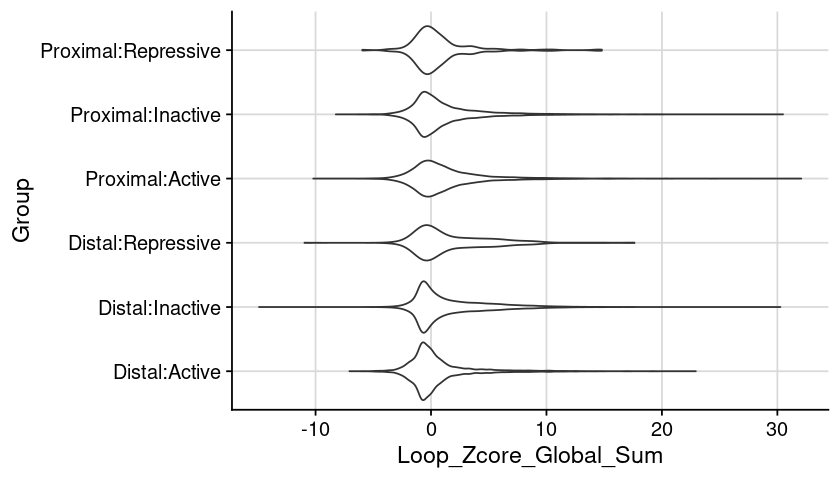

In [29]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_Global_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

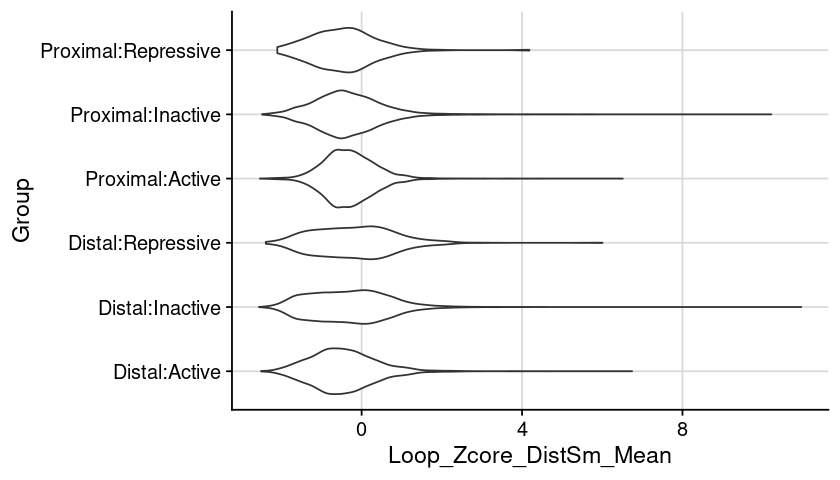

In [27]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Mean, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

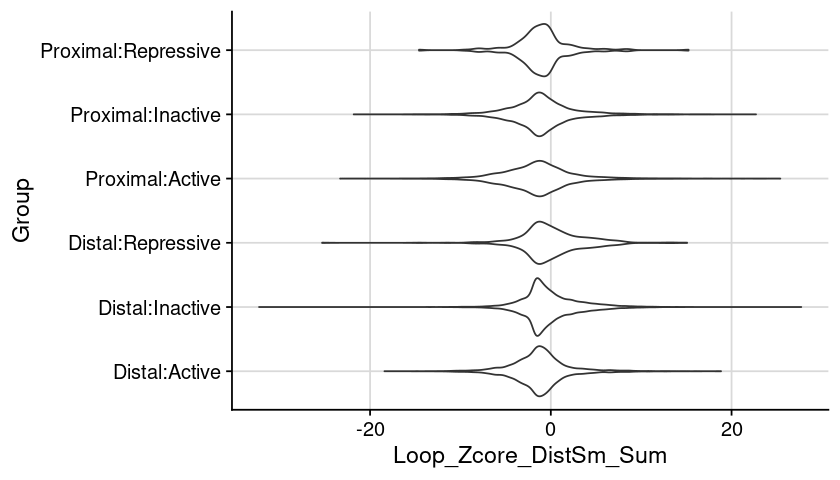

In [28]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

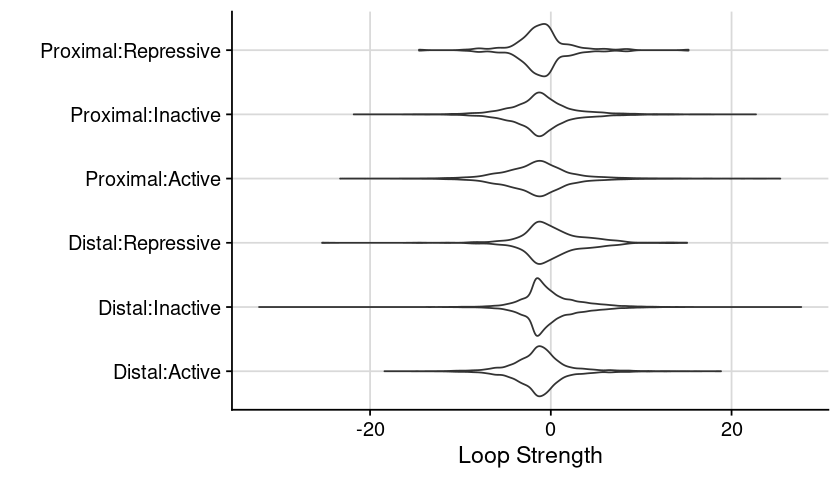

In [14]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm_Sum, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Strength", y = "")
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

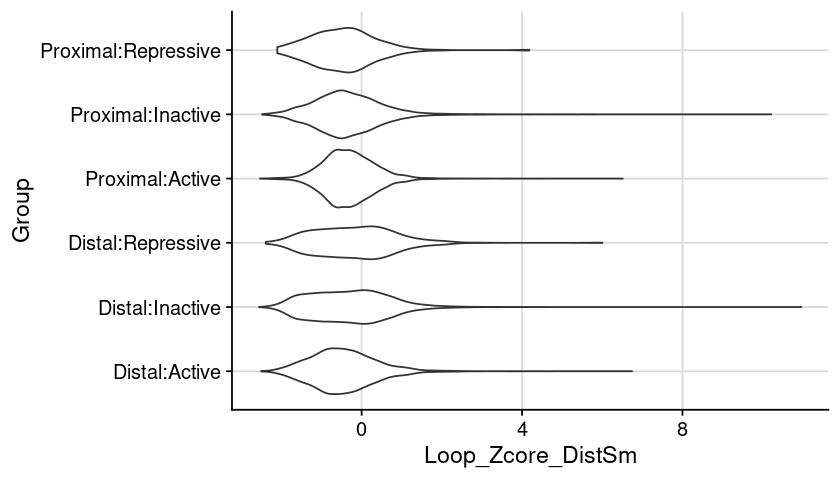

In [15]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm, y=Group)) +
        geom_violin() +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

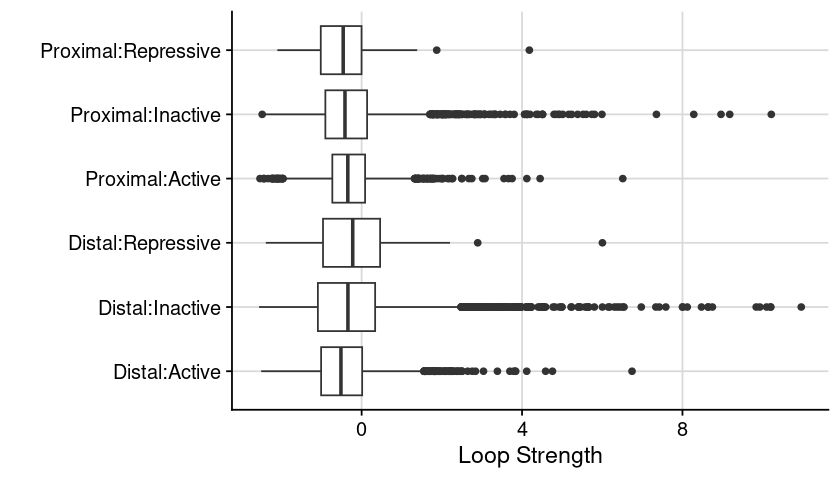

In [21]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm, y=Group)) +
        geom_boxplot() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Strength", y = "")
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

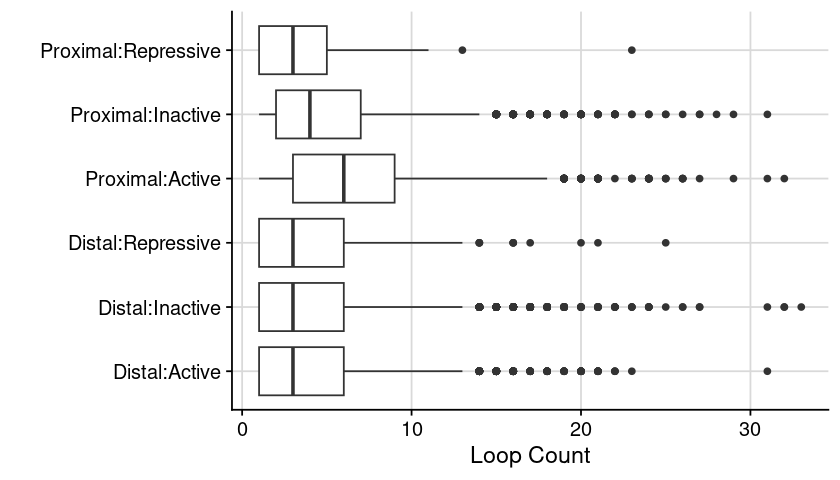

In [18]:
lst = lst_dat_region_annot_merge
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Count, y=Group)) +
        geom_boxplot() +
        theme_cowplot() +
        background_grid() +
        labs(x = "Loop Count", y = "")
    return(gpt)
})

gpt = lst[[1]]

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)